In [221]:
# Import neccessary libraries
import itertools
import re

import pandas as pd
import numpy as np

# For graph plot
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

# For feature scaling and selection
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, MaxAbsScaler
from sklearn.feature_selection import mutual_info_regression, SequentialFeatureSelector
from sklearn.svm import SVR
from mrmr import mrmr_regression

# For DLNM model
from statsmodels.gam.gam_cross_validation.cross_validators import KFold
import statsmodels.api as sm
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.gam.gam_cross_validation.gam_cross_validation import MultivariateGAMCVPath
from statsmodels.genmod.families.links import log
from statsmodels.gam.smooth_basis import GenericSmoothers
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from pydlnm.utils import logknots
from dlnm import crossbasis, plot_crosspred, cb_pen

from statsmodels.stats.outliers_influence import variance_inflation_factor


In [222]:
# Function for constructing the CrossBasis matrix
def crossbasis_construct(dataframe, col_lst, max_lag, setting_lst): 
    # setting_lst include the values for the degree and degree of freedom (df) for both exposure and lag dimension in order
    
    # Initlialize the list to place cross basis matrices
    cb_list = []

    # Construct cross basis for each exposure variables
    for col in col_lst:
        tmp_cb = CrossBasis(dataframe[col].values, lag=max_lag, 
                                argvar={"fun": "bs", "degree": setting_lst[0], "df": setting_lst[1]}, 
                                arglag={"fun": "bs", "degree": setting_lst[2], "df": setting_lst[3]})
        cb_list.append(tmp_cb)

    X_exposure = np.concat(cb_list, axis=1)

    # Construct the DataFrame object for later model construction 
    model_data = np.concat([dataframe.to_numpy(), X_exposure], axis=1)
    model_data = pd.DataFrame(model_data)

    # Rename the columns of the mode_data DataFrame 
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(tmp_cb.shape[1])]
    model_data.columns = [n for n in dataframe.columns if n!="From"] + exp_name_list

    # Fill in 0 for the missing value(s)
    model_data[exp_name_list] = model_data[exp_name_list].fillna(0)

    # Return the variables that need to be used 
    return model_data, exp_name_list, cb_list

In [223]:
# Function for constructing the smoothers 
def smoothers_construct(dataframe, bs_dict, cs_dict):
    # bs_dict and cs_dict contains the name, degree and df for the spline function constructions needed 
    
    bs_list = []
    # Use B spline for 'time' and 'stringency index'
    for i in range(len(bs_dict["name"])):
        tmp_bs = UnivariateBSplines(dataframe[bs_dict["name"][i]], df=bs_dict["df"][i], degree=bs_dict["degree"][i], include_intercept=False, variable_name=bs_dict["name"][i])
        bs_list.append(tmp_bs)
    
    # Use Cubic Cyclic Spline for 'Week'
    cs = UnivariateCubicCyclicSplines(dataframe[cs_dict["name"]], df=cs_dict["df"], constraints="center", variable_name=cs_dict["name"])

    # Group the two spline functions together to form a single smoother variable
    sm_weights = bs_list + [cs]
    X_smooth = dataframe[bs_dict["name"]+[cs_dict["name"]]]
    smoothers = GenericSmoothers(X_smooth, sm_weights)

    # Return the smoother variable
    return smoothers

In [249]:
# Function for constructing GAM model with Negative Binomial family 
def NB_GAM_model(dataframe, tar_var, exp_names, smoothers, a): 
    # Initializa the formula
    formula = f"{tar_var} ~ {exp_names} + pandemic_flag"

    # Build and fit the model
    NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=a, family=sm.families.NegativeBinomial(alpha=5.0))
    result = NegativeBinomial_gam_model.fit()
    # result = NegativeBinomial_gam_model.fit_regularized(method="l1_slsqp", alpha=1.0)
        # no penalization for Negative Binomial

    # Return the model and the result 
    return NegativeBinomial_gam_model, result

In [225]:
# Function for 
def pred_cal(result, dataframe, cb_lst, mete_lst, i):
    n_cb_cols = cb_lst[i].shape[1]
    start_idx = sum(cb.shape[1] for cb in cb_lst[:i])
    end_idx = start_idx+n_cb_cols
    cb_coef = result.params.values[start_idx:end_idx]
    cb_vcov = result.cov_params().iloc[start_idx:end_idx, start_idx:end_idx]
    at = np.linspace(dataframe[mete_lst[i]].min(), dataframe[mete_lst[i]].max(), 100)
    cen = dataframe[mete_lst[i]].median()
    pred = crosspred(basis=cb_lst[i], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)
    
    print(f"{mete_lst[i]} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")

    return pred

In [226]:
# Function for plotting the 3D graph 
def graph_3Dplot(pred, exp):
    fig = plot_crosspred(pred, ptype="3d")

    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel(exp, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Residual Risk (RR)", labelpad=10)
    ax.set_yticks(np.linspace(0, 4, pred.matRRfit.shape[1]))

    collections = ax.collections[0]
    vmin, vmax = collections.get_array().min(), collections.get_array().max()

    collections.set_clim(vmin, vmax)
    cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
    cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)

    plt.tight_layout()
    plt.show()

In [227]:
# Function for plotting the exposure-response slice plot
def graph_expresponseplot(pred, exp):
    fig = plot_crosspred(pred, ptype="overall")
    cen = df[exp].median()

    ax = fig.gca()

    ax.axvline(x=cen, color='black', linestyle=':', linewidth=1.2, label=f'Centering {exp} ({cen:.1f})')
    ax.set_title('Overall Cumulative Exposure-Response Association', fontsize=14, pad=15)
    ax.set_xlabel(exp, fontsize=12)
    ax.legend(loc="best", frameon=True)

    plt.show()

In [228]:
# Function for plotting the lag-response slice plot
def graph_lagresponseplot(pred, target_var):
    fig = plot_crosspred(
        pred, 
        ptype="slices", 
        var=target_var
    )

    ax = fig.gca()

    ax.set_title(f"Lag-Response Curve at {target_var}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color='gray', linestyle='--', alpha=0.7) # Add baseline at RR=1
    
    plt.show()

In [229]:
# Function for all the three plots at the same time 
def graph_plot(pred, exp, val):
    graph_3Dplot(pred, exp)
    graph_expresponseplot(pred, exp)
    graph_lagresponseplot(pred, val)

In [230]:
def alpha_tune(dataframe, tar_var, exp_names, smoothers, crit, meth):
    model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [10, 10 , 10])
    best_a = model.select_penweight(criterion=crit, method=meth, start_params=np.array([10, 10, 10]))
    return best_a

In [231]:
# Find the degree and degrees of freedom for the CrossBasis
def cb_setting_performance(dataframe, exp_col, setting_options):
    best_setting_idx = 0
    performance = []
    for setting in setting_options:
        model_data, exp_name_list, cb_list = crossbasis_construct(dataframe, exp_col, 4, setting)
        smoothers = smoothers_construct(model_data, {"name": ["time", "ContainmentHealthIndex_Average"], "degree": [3, 3], "df": [6, 4]}, {"name": "Week", "df": 4})
        initial_alpha = [50, 50, 50]
        model, result = NB_GAM_model(model_data, "H1",  " + ".join(exp_name_list), smoothers, initial_alpha)
        print(f"AIC value for the settings {setting}: {result.aic}")
        performance.append([result.aic, result.deviance, result.null_deviance, result.df_resid, result.df_model])

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_setting_idx][0]:
            best_setting_idx = i

    return setting_options[best_setting_idx]


In [232]:
# Find the degree and degrees of freedom for the CrossBasis
def smoother_setting_performance(dataframe, exp_name_lst, setting_options):
    best_setting_idx = 0
    performance = []
    for setting in setting_options:
        smoothers = smoothers_construct(dataframe, {"name": ["time", "ContainmentHealthIndex_Average"], "degree": [3, 3], "df": [setting[0], setting[1]]}, {"name": "Week", "df": setting[2]})
        initial_alpha = [150, 150, 150]
        model, result = NB_GAM_model(dataframe, "H1",  " + ".join(exp_name_lst), smoothers, initial_alpha)
        print(f"AIC value for the settings {setting}: {result.aic}")
        performance.append([result.aic, result.deviance, result.null_deviance, result.df_resid, result.df_model])

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_setting_idx][0]:
            best_setting_idx = i

    return setting_options[best_setting_idx]


In [ ]:
def smoother_setting_performance(dataframe, exp_name_lst, setting_options, 
                                  tar_var="H1", initial_alpha=None):
    """
    Safer grid search for smoother degrees of freedom.
    Returns the best setting according to BIC + some diagnostics.
    """
    if initial_alpha is None:
        initial_alpha = [150.0, 150.0, 150.0]   # stronger penalty = more stable
    
    performance = []
    successful_settings = []
    
    for setting in setting_options:
        time_df, chi_df, week_df = setting
        print(f"\nTrying smoother dfs: time={time_df}, CHI={chi_df}, Week={week_df}")
        
        try:
            smoothers = smoothers_construct(
                dataframe,
                bs_dict={
                    "name": ["time", "ContainmentHealthIndex_Average"],
                    "degree": [3, 3],
                    "df": [time_df, chi_df]
                },
                cs_dict={"name": "Week", "df": week_df}
            )
            
            model, result = NB_GAM_model(
                dataframe, 
                tar_var, 
                " + ".join(exp_name_lst), 
                smoothers, 
                initial_alpha
            )
            
            # Collect useful diagnostics
            edf = result.edf if hasattr(result, "edf") else None
            pearson_ratio = result.pearson_chi2 / result.df_resid
            
            perf = {
                "setting": setting,
                "aic": result.aic,
                "bic": result.bic,
                "deviance": result.deviance,
                "df_resid": result.df_resid,
                "edf": edf,
                "pearson_ratio": pearson_ratio
            }
            performance.append(perf)
            successful_settings.append(setting)
            
            print(f"  → AIC={result.aic:.1f} | BIC={result.bic:.1f} | "
                  f"Pearson χ²/df={pearson_ratio:.2f} | EDF={edf}")
            
        except Exception as e:
            print(f"  → FAILED: {type(e).__name__}: {e}")
            continue
    
    if not performance:
        raise RuntimeError("All smoother settings failed. Reduce dfs or increase alpha.")
    
    # Select by BIC (more conservative than AIC)
    best = min(performance, key=lambda x: x["bic"])
    
    print("\n" + "="*60)
    print(f"Best smoother setting (by BIC): {best['setting']}")
    print(f"  BIC = {best['bic']:.1f}, AIC = {best['aic']:.1f}")
    print(f"  Pearson χ²/df = {best['pearson_ratio']:.2f}")
    print(f"  EDF = {best['edf']}")
    print("="*60)
    
    return best["setting"], performance

---

In [233]:
# Import data and basic settings
df = pd.read_csv("data.csv")

df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag"]

# Drop unnecessary columns
df.drop(columns=["From"], inplace=True)

# Add a new column <"time"> to df 
df["time"] = np.arange(1, len(df)+1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [234]:
# After doing VIF test
mete_col = ["DPT", "WS", "UV"]
mete_col = ["WS", "temp"]

df = df[mete_col + flu_col + spline_col + ["pandemic_flag"]]

In [235]:
# overview for df 
display(df.head())
display(df.describe().T)

,WS,temp,H1,H3,B,AandB,ContainmentHealthIndex_Average,Week,time,pandemic_flag
0,7.35,28.15,1,12,3.0,19,0.0,36,1,0.0
1,10.50,26.70,0,6,4.0,15,0.0,37,2,0.0
2,13.45,26.40,0,4,4.0,13,0.0,38,3,0.0
3,13.25,25.90,0,2,6.0,10,0.0,39,4,0.0
4,10.05,25.95,0,6,2.0,8,0.0,40,5,0.0


,count,mean,std,min,25%,50%,75%,max
WS,1253.0,10.074062,1.811932,5.55,8.8,10.0,11.2,17.80
temp,1253.0,23.383599,5.005770,8.90,19.1,24.4,28.0,31.70
H1,1253.0,69.613727,189.083854,0.00,0.0,4.0,47.0,1999.00
H3,1253.0,115.727055,233.728958,0.00,5.0,28.0,125.0,2560.00
B,1252.0,44.593450,131.615377,0.00,3.0,12.5,41.0,1978.00
AandB,1253.0,261.437350,439.621172,0.00,27.0,103.0,305.0,4679.00
ContainmentHealthIndex_Average,1253.0,8.128132,21.983305,0.00,0.0,0.0,0.0,82.14
Week,1253.0,26.605746,15.077257,1.00,14.0,27.0,40.0,53.00
time,1253.0,627.000000,361.854252,1.00,314.0,627.0,940.0,1253.00
pandemic_flag,1253.0,0.131684,0.338282,0.00,0.0,0.0,0.0,1.00


In [240]:
# Grid for the CrossBasis settings 
degrees_var = [2, 3]
dfs_var     = [3, 4, 5, 6]
degrees_lag = [2, 3]
dfs_lag     = [3, 4, 5]
setting_options = list(itertools.product(degrees_var, dfs_var, degrees_lag, dfs_lag))

# Find the best Cross Basis settings
best_cb_setting = cb_setting_performance(df, mete_col, setting_options)
print(f"The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: \n{best_cb_setting}")

AIC value for the settings (2, 3, 2, 3): 9261.968993838347
AIC value for the settings (2, 3, 2, 4): 9273.20414418175
AIC value for the settings (2, 3, 2, 5): 9282.966339959006
AIC value for the settings (2, 3, 3, 3): 9273.204144181742
AIC value for the settings (2, 3, 3, 4): 9273.204144181742
AIC value for the settings (2, 3, 3, 5): 9282.966339959003
AIC value for the settings (2, 4, 2, 3): 9255.190194041783
AIC value for the settings (2, 4, 2, 4): 9270.37764413574
AIC value for the settings (2, 4, 2, 5): 9284.439281211136
AIC value for the settings (2, 4, 3, 3): 9270.377644135744
AIC value for the settings (2, 4, 3, 4): 9270.377644135744
AIC value for the settings (2, 4, 3, 5): 9284.439281211147
AIC value for the settings (2, 5, 2, 3): 9244.963201394476
AIC value for the settings (2, 5, 2, 4): 9270.158761426446
AIC value for the settings (2, 5, 2, 5): 9289.836107765259
AIC value for the settings (2, 5, 3, 3): 9270.158761426468
AIC value for the settings (2, 5, 3, 4): 9270.158761426468

In [241]:
model_data, exp_name_list, cb_list = crossbasis_construct(df, mete_col, 4, best_cb_setting)

display(model_data.head())
display(model_data.describe())

,WS,temp,H1,H3,B,AandB,ContainmentHealthIndex_Average,Week,time,pandemic_flag,...,temp_basis_2,temp_basis_3,temp_basis_4,temp_basis_5,temp_basis_6,temp_basis_7,temp_basis_8,temp_basis_9,temp_basis_10,temp_basis_11
0,7.35,28.15,1.0,12.0,3.0,19.0,0.0,36.0,1.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
1,10.50,26.70,0.0,6.0,4.0,15.0,0.0,37.0,2.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
2,13.45,26.40,0.0,4.0,4.0,13.0,0.0,38.0,3.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
3,13.25,25.90,0.0,2.0,6.0,10.0,0.0,39.0,4.0,0.0,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
4,10.05,25.95,0.0,6.0,2.0,8.0,0.0,40.0,5.0,0.0,...,0.043339,0.626117,0.386951,0.423058,1.13645,0.786536,1.249768,0.021549,0.025264,0.158834


,WS,temp,H1,H3,B,AandB,ContainmentHealthIndex_Average,Week,time,pandemic_flag,...,temp_basis_2,temp_basis_3,temp_basis_4,temp_basis_5,temp_basis_6,temp_basis_7,temp_basis_8,temp_basis_9,temp_basis_10,temp_basis_11
count,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,...,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,10.074062,23.383599,69.613727,115.727055,44.593450,261.437350,8.128132,26.605746,627.000000,0.131684,...,0.361559,0.548144,0.365728,0.549002,0.736471,0.491025,0.737211,0.139564,0.092650,0.137842
std,1.811932,5.005770,189.083854,233.728958,131.615377,439.621172,21.983305,15.077257,361.854252,0.338282,...,0.352916,0.245690,0.162532,0.244900,0.451849,0.300769,0.452130,0.208991,0.137972,0.205457
min,5.550000,8.900000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,8.800000,19.100000,0.000000,5.000000,3.000000,27.000000,0.000000,14.000000,314.000000,0.000000,...,0.030062,0.316199,0.216947,0.327591,0.259606,0.173865,0.265868,0.000000,0.000000,0.000000
50%,10.000000,24.400000,4.000000,28.000000,12.500000,103.000000,0.000000,27.000000,627.000000,0.000000,...,0.211699,0.573103,0.385024,0.569522,0.854771,0.563688,0.839535,0.003758,0.002118,0.003968
75%,11.200000,28.000000,47.000000,125.000000,41.000000,305.000000,0.000000,40.000000,940.000000,0.000000,...,0.722820,0.777959,0.521853,0.781122,1.182436,0.786917,1.182944,0.258368,0.178512,0.245250
max,17.800000,31.700000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,53.000000,1253.000000,1.000000,...,0.985769,0.910952,0.610075,0.912780,1.288529,0.861315,1.290930,1.175289,0.743595,1.001667


In [242]:
X = pd.DataFrame(model_data.drop(columns=["B", "WS", "temp"]))

vif = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})

display(vif.sort_values("VIF", ascending=False))

,Variable,VIF
26,temp_basis_7,108.135845
20,temp_basis_1,96.153406
27,temp_basis_8,60.405596
25,temp_basis_6,59.270535
21,temp_basis_2,57.435992
19,temp_basis_0,56.974702
8,WS_basis_1,19.281920
29,temp_basis_10,18.845301
23,temp_basis_4,17.202757
14,WS_basis_7,16.389927


In [ ]:
# to-do, failed with SingularMatrixWarning

# Grid for the CrossBasis settings 
time_df = [4, 6, 8, 10]
chi_df = [4, 5, 6]
week_df = [4, 5]
smoother_options = list(itertools.product(time_df, chi_df, week_df))

best_smoother_setting = smoother_setting_performance(model_data, exp_name_list, smoother_options)
print(f"The best degrees of freedom for the smoother terms [time, CH_index, week]: \n{best_smoother_setting}")


In [243]:
smoothers = smoothers_construct(model_data, {"name": ["time", "ContainmentHealthIndex_Average"], "degree": [3, 3], "df": [5, 4]}, {"name": "Week", "df": 3})


In [244]:
best_a_bic = alpha_tune(model_data, "H1", " + ".join(exp_name_list), smoothers, "bic", "nm")

print(best_a_bic[1])
print(f"alpha {best_a_bic[0]} is the best tested with BIC")

Optimization terminated successfully.
         Current function value: 9977.331195
         Iterations: 162
         Function evaluations: 305
(array([15.10639194, -9.81345767,  9.04285391]), np.float64(9977.331195024648), 162, 305, 0)
alpha [3.63598985e+06 5.47103491e-05 8.45788068e+03] is the best tested with BIC


In [245]:
best_a_gcv = alpha_tune(model_data, "H1", " + ".join(exp_name_list), smoothers, "gcv", "nm")

print(best_a_gcv[1])
print(f"alpha {best_a_gcv[0]} is the best tested with GCV")

Optimization terminated successfully.
         Current function value: 1.000000
         Iterations: 64
         Function evaluations: 180
(array([ -28.47892923, -210.16783167,   86.21061366]), np.float64(1.0), 64, 180, 0)
alpha [4.28309971e-13 5.31215125e-92 2.75926743e+37] is the best tested with GCV


In [246]:
for nb_alpha in [1.0, 2.0, 5.0, 10.0, 15.0]:
    model = GLMGam.from_formula(
        f"H1 ~ {' + '.join(exp_name_list)} + pandemic_flag",
        data=model_data,
        smoother=smoothers,
        alpha=best_a_bic[0],          # the GAM penalties
        family=sm.families.NegativeBinomial(alpha=nb_alpha)
    )
    result = model.fit()
    pearson_ratio = result.pearson_chi2 / result.df_resid
    print(f"NB alpha={nb_alpha:5.1f} :\n Pearson χ²/df = {pearson_ratio:.2f}")

NB alpha=  1.0 :
 Pearson χ²/df = 3.88
NB alpha=  2.0 :
 Pearson χ²/df = 2.16
NB alpha=  5.0 :
 Pearson χ²/df = 0.98
NB alpha= 10.0 :
 Pearson χ²/df = 0.56
NB alpha= 15.0 :
 Pearson χ²/df = 0.40


In [250]:
model_bic, result_bic = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_bic[0])
print(result_bic.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                  1218.91
Model Family:        NegativeBinomial   Df Model:                        33.09
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4564.0
Date:                Mon, 16 Nov 2026   Deviance:                       898.69
Time:                        20:18:33   Pearson chi2:                 1.19e+03
No. Iterations:                  1000   Pseudo R-squ. (CS):             0.4348
Covariance Type:            nonrobust                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [251]:
for s in smoothers.smoothers:
    if getattr(s, "der_basis", None) is None:
        s.der_basis = np.zeros_like(s.basis)
    if getattr(s, "der2_basis", None) is None:
        s.der2_basis = np.zeros_like(s.basis)

best_a_kfold = model.select_penweight_kfold()
print(f"alpha {best_a_kfold[0]} is the best tested with kfold")

alpha (np.float64(10000000.0), np.float64(630.957344480193), np.float64(1.0)) is the best tested with kfold


In [252]:
# Model diagnotics / Goodness-of-fit
print(f"AIC: {result_bic.aic}")
print(f"BIC: {result_bic.bic}")
print(f"Deviance: {result_bic.deviance}")
print(f"Pearson Chi2: {result_bic.pearson_chi2}")
print(f"Scale/Dispersion: {result_bic.scale}")
print(f"Effective degree of freedom: \n{result_bic.edf}")
print(f"Total EDF: {result_bic.edf.sum()}")

AIC: 9196.089948933495
BIC: 9371.080449379902
Deviance: 898.6856151585637
Pearson Chi2: 1192.8266669411655
Scale/Dispersion: 1.0
Effective degree of freedom: 
[0.95894141 0.24861694 1.55643413 0.57693701 0.88439119 1.19902137
 0.84010111 0.90742383 0.99904288 0.95371364 1.40365168 0.8539472
 0.64451512 1.1764471  0.43211383 1.04344744 0.93118781 0.67308959
 0.89371388 1.77538916 0.59523605 1.30962679 1.15829821 1.77344758
 1.15460519 1.14482221 1.6228004  0.22161052 1.08925529 1.12636477
 2.34470182 0.64346845 0.59492705 0.2896198  0.06839631]
Total EDF: 34.08930675027706


In [253]:
X = np.asarray(model_bic.exog)

print("Design matrix shape:", X.shape)
print("Condition number:", np.linalg.cond(X))
print("Matrix rank:", np.linalg.matrix_rank(X))

Design matrix shape: (1253, 35)
Condition number: 154.4280790502975
Matrix rank: 35


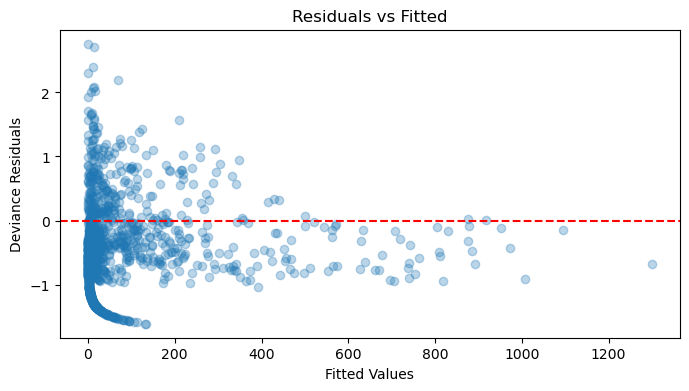

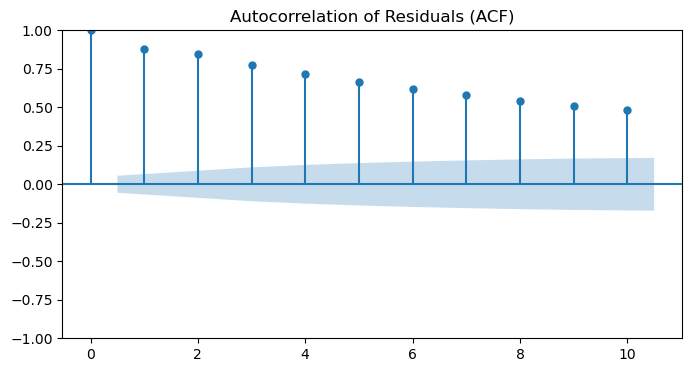

In [254]:
# Residual diagnotics

# Extract deviance residuals
residuals = result_bic.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result_bic.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [255]:
model_gcv, result_gcv = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_gcv[0])


In [256]:
# Model diagnotics / Goodness-of-fit
print(f"AIC: {result_gcv.aic}")
print(f"BIC: {result_gcv.bic}")
print(f"Deviance: {result_gcv.deviance}")
print(f"Pearson Chi2: {result_gcv.pearson_chi2}")
print(f"Scale/Dispersion: {result_gcv.scale}")
print(f"Effective degree of freedom: \n{result_gcv.edf}")
print(f"Total EDF: {result_gcv.edf.sum()}")

AIC: 39112.099550342835
BIC: 39112.099550342835
Deviance: 30882.87383006844
Pearson Chi2: 8443552.166666592
Scale/Dispersion: 1.0
Effective degree of freedom: 
[6.37475569e-16 4.30821542e-16 1.93590292e-16 4.35724854e-16
 3.43437868e-16 1.53001784e-16 3.45628655e-16 6.77078038e-17
 2.89512554e-17 6.67053680e-17 1.36763677e-18 3.77413721e-19
 8.65072137e-19 2.31250553e-16 1.06525592e-16 2.46313657e-16
 2.39225938e-16 1.05421711e-16 2.43130340e-16 3.44747785e-16
 1.47039308e-16 3.28846312e-16 4.91462467e-17 2.06633024e-17
 3.23813380e-17 3.02717929e-17 2.38567509e-17 4.78906915e-17
 1.08814524e-16 1.21839519e-16 3.00209402e-18 1.14895299e-18
 2.72417816e-19 1.26650997e-32 2.67389894e-32]
Total EDF: 5.137443939181103e-15


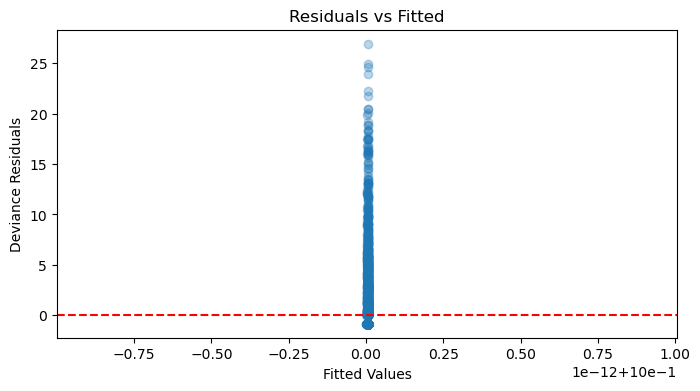

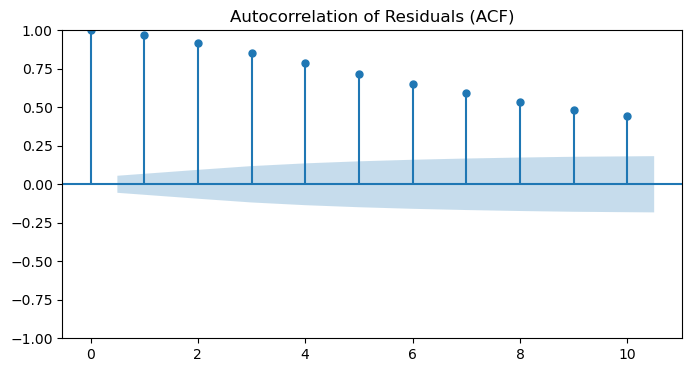

In [257]:
# Residual diagnotics

# Extract deviance residuals
residuals = result_gcv.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result_gcv.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [258]:
model_kfold, result_kfold = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_kfold[0])


In [259]:
# Model diagnotics / Goodness-of-fit
print(f"AIC: {result_kfold.aic}")
print(f"BIC: {result_kfold.bic}")
print(f"Deviance: {result_kfold.deviance}")
print(f"Pearson Chi2: {result_kfold.pearson_chi2}")
print(f"Scale/Dispersion: {result_kfold.scale}")
print(f"Effective degree of freedom: \n{result_kfold.edf}")
print(f"Total EDF: {result_kfold.edf.sum()}")

AIC: 9245.904576789966
BIC: 9412.705424068261
Deviance: 951.6910402104795
Pearson Chi2: 1300.5313915296629
Scale/Dispersion: 1.0
Effective degree of freedom: 
[0.38345661 0.69750572 1.38822595 1.13324885 1.06170387 0.86712336
 0.87890749 1.01854645 1.01546041 1.10220024 1.306647   0.89393916
 0.73525638 0.89101955 0.46035237 0.95613866 0.98678956 0.64425004
 0.67986322 1.3233945  0.5067275  0.9401541  1.28973361 1.38073536
 0.88547304 0.28203602 1.43444089 0.17715003 0.90287314 0.94116331
 0.53050315 0.35768188 0.9808397  0.91446821 2.54589884]
Total EDF: 32.493908152558866


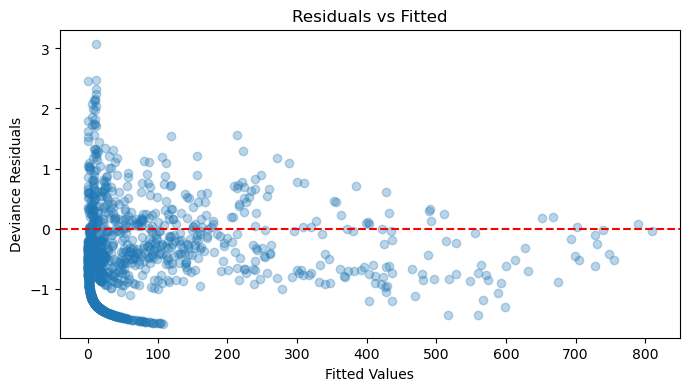

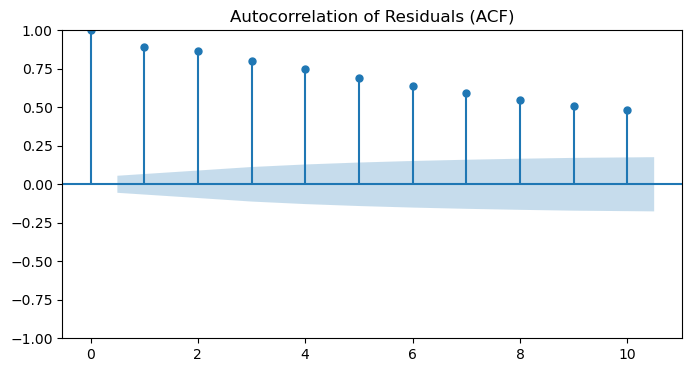

In [260]:
# Residual diagnotics

# Extract deviance residuals
residuals = result_kfold.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result_kfold.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [261]:
# Comparison for using BIC / GCV / Kfold for choosing alpha 
results = {}

results["BIC"] = {"alpha": best_a_bic[0], "AIC": result_bic.aic, "BIC": result_bic.bic, "GCV": result_bic.gcv, "EDF": result_bic.edf.sum()}
results["GCV"] = {"alpha": best_a_gcv[0], "AIC": result_gcv.aic, "BIC": result_gcv.bic, "GCV": result_gcv.gcv, "EDF": result_gcv.edf.sum()}
results["KFold"] = {"alpha": best_a_kfold[0], "AIC": result_kfold.aic, "BIC": result_kfold.bic, "GCV": result_kfold.gcv, "EDF": result_kfold.edf.sum()}

print("Alpha values comparison using BIC/GCV/Kfold: ")
display(pd.DataFrame(results).T)

Alpha values comparison using BIC/GCV/Kfold: 


,alpha,AIC,BIC,GCV,EDF
BIC,"[3635989.854530271, 5.471034909394697e-05, 845...",9196.089949,9371.080449,1.056716,34.089307
GCV,"[4.2830997110559385e-13, 5.312151252634914e-92...",39112.09955,39112.09955,1.0,0.0
KFold,"(10000000.0, 630.957344480193, 1.0)",9245.904577,9412.705424,1.053955,32.493908


WS RR range: 0.051 to 19.693


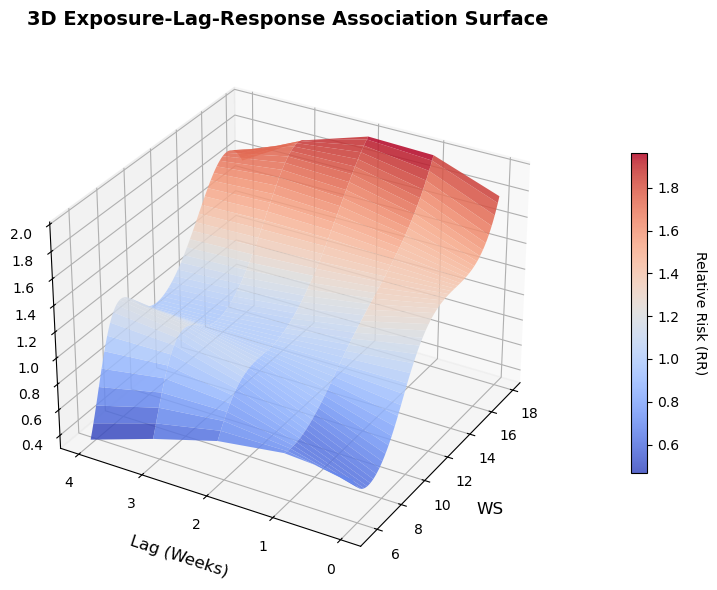

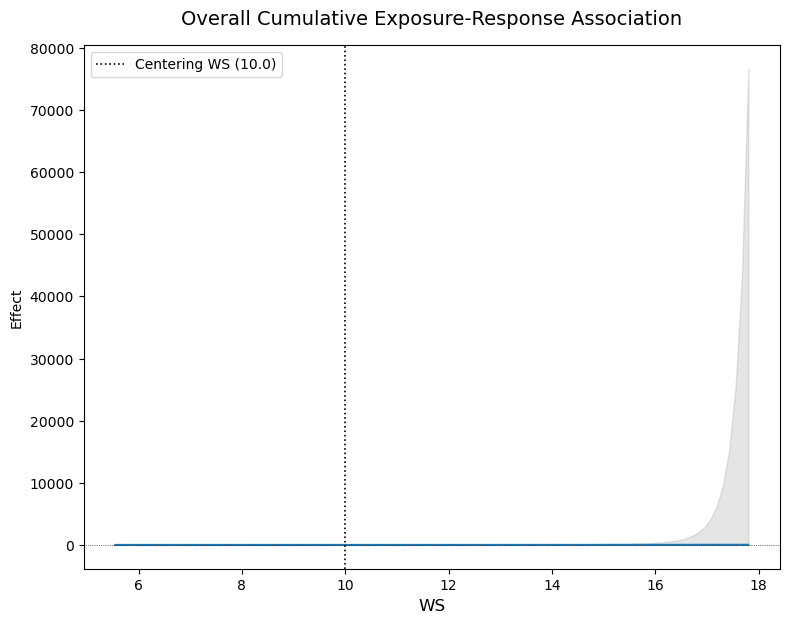

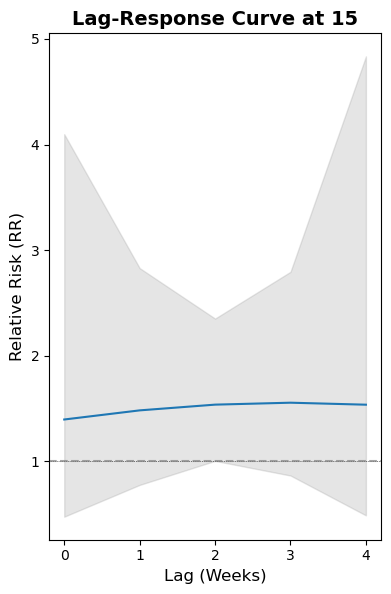

temp RR range: 0.778 to 36.262


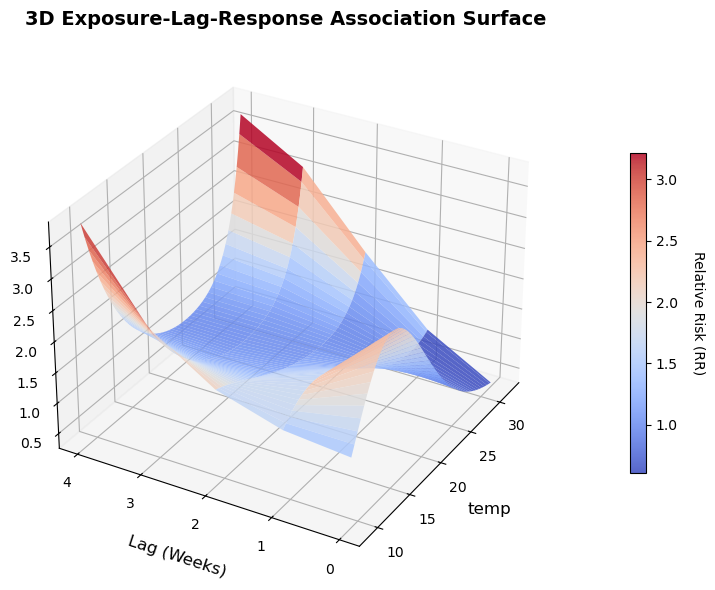

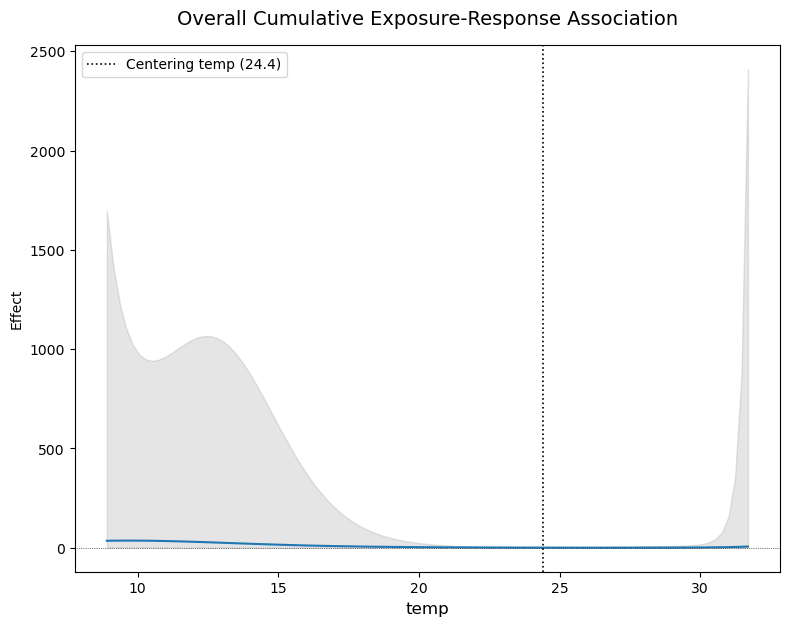

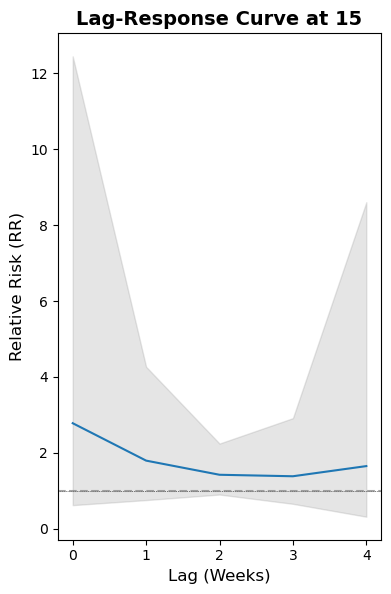

In [262]:
# Graph plots
for i in range(len(mete_col)):
    pred = pred_cal(result_bic, model_data, cb_list, mete_col, i)
    graph_plot(pred, mete_col[i], 15)

WS RR range: 1.000 to 1.000


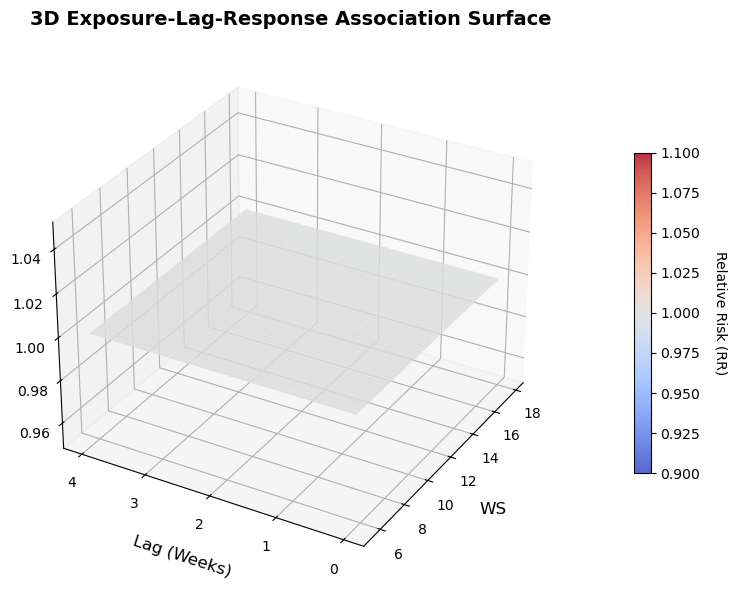

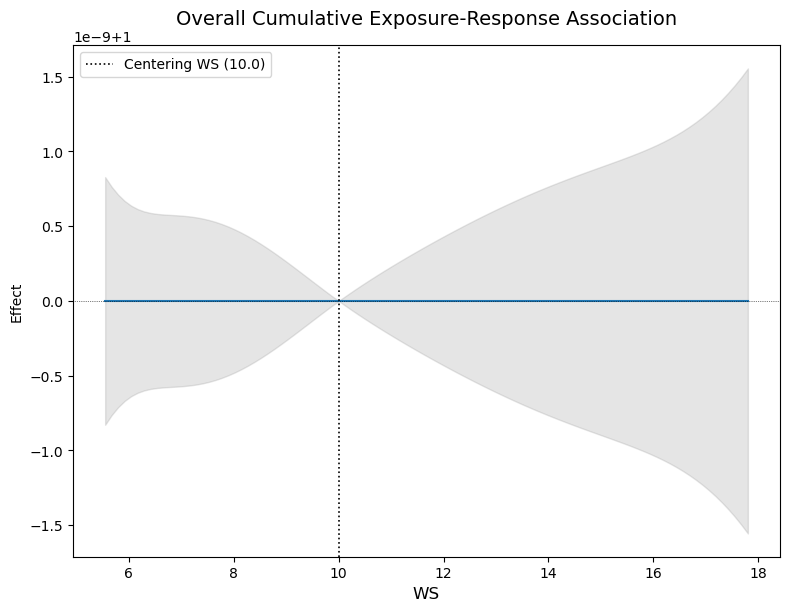

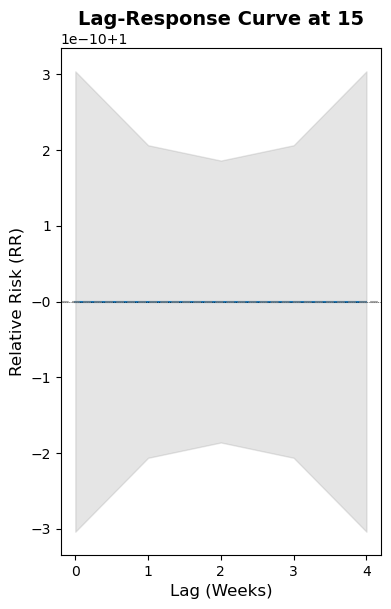

temp RR range: 1.000 to 1.000


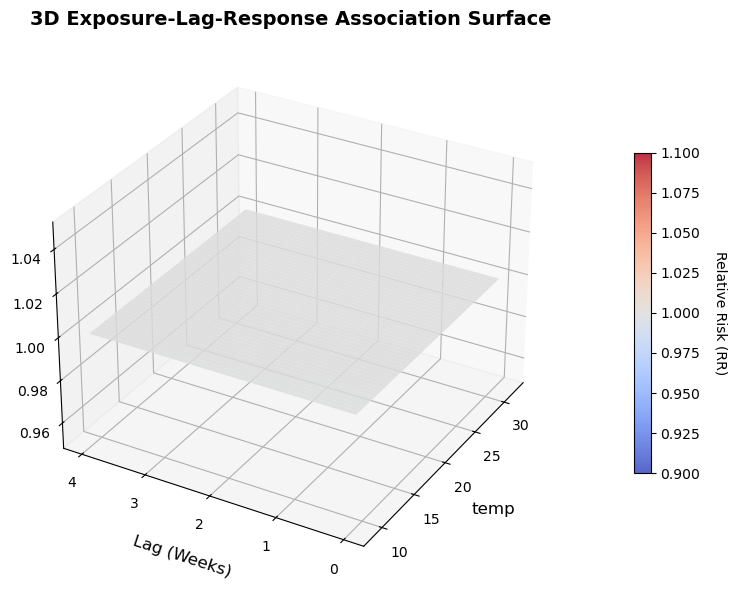

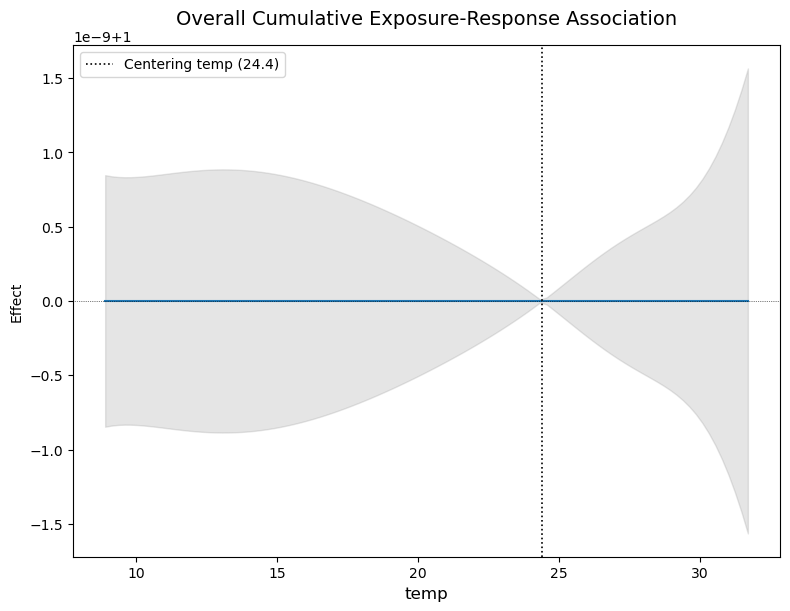

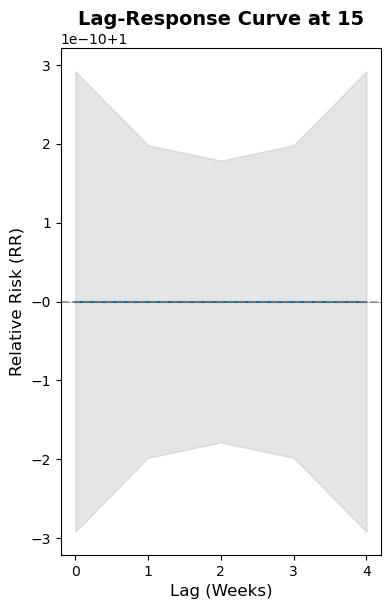

In [263]:
# Graph plots
for i in range(len(mete_col)):
    pred = pred_cal(result_gcv, model_data, cb_list, mete_col, i)
    graph_plot(pred, mete_col[i], 15)

WS RR range: 0.158 to 29.548


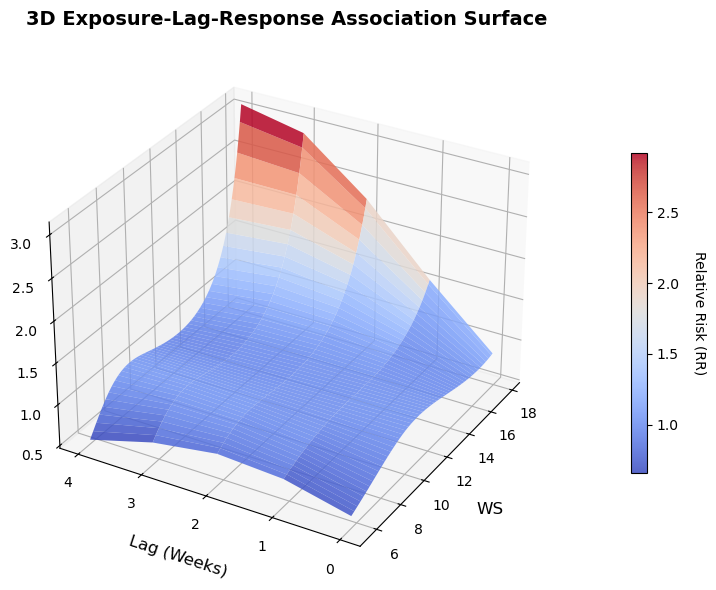

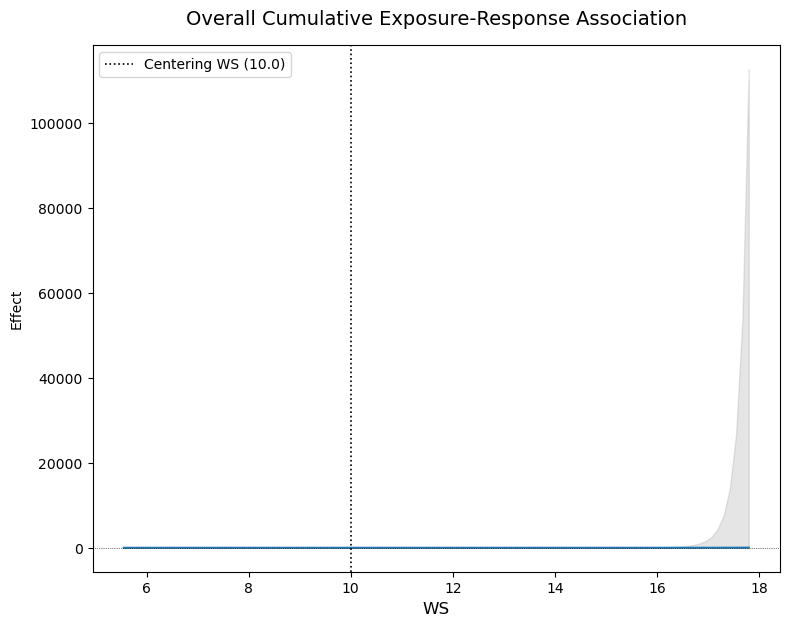

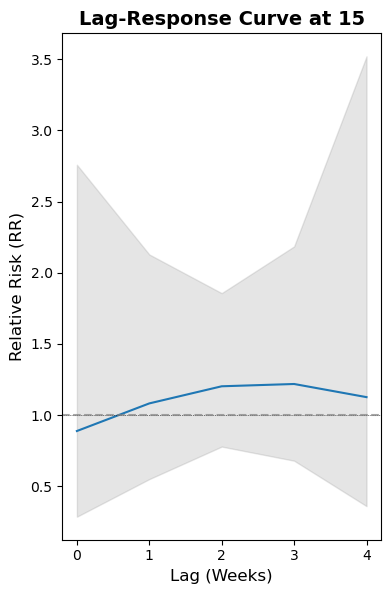

temp RR range: 0.886 to 226.976


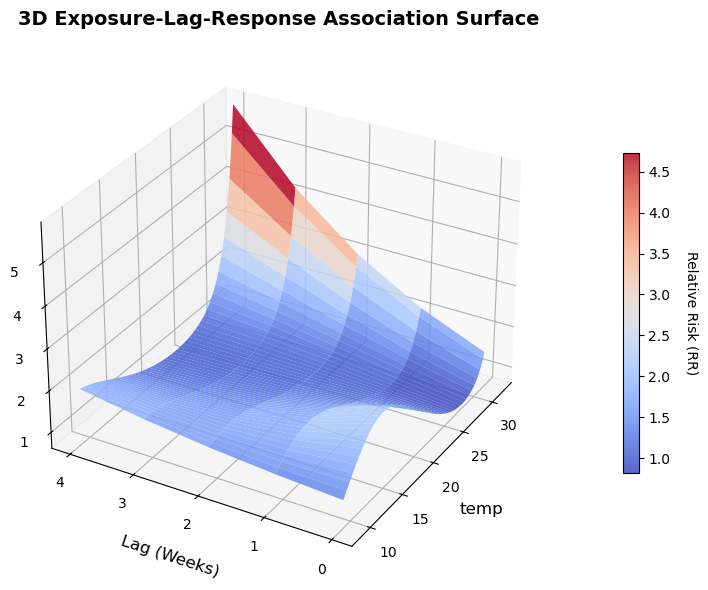

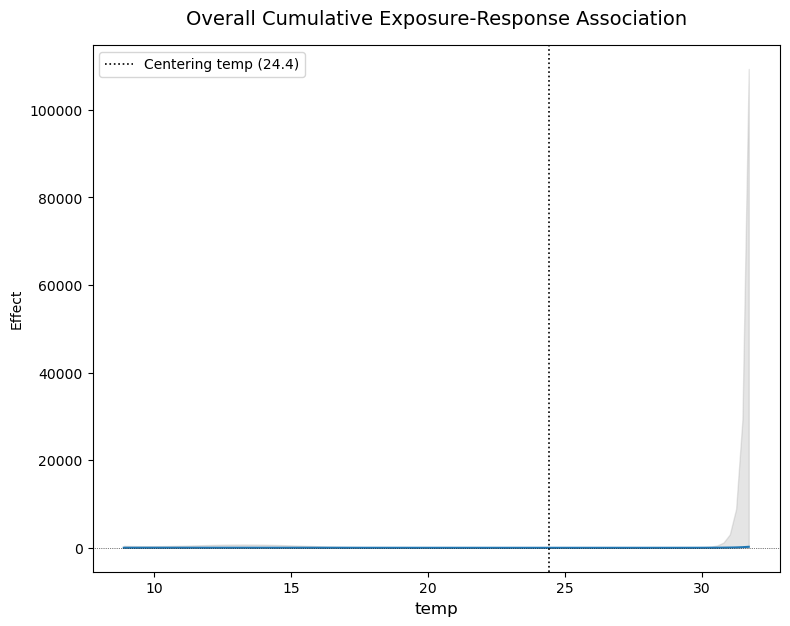

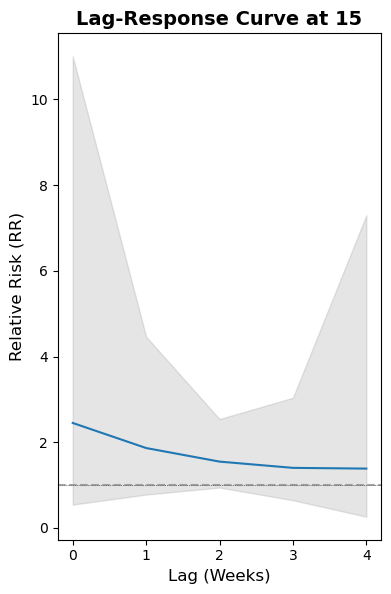

In [264]:
# Graph plots
for i in range(len(mete_col)):
    pred = pred_cal(result_kfold, model_data, cb_list, mete_col, i)
    graph_plot(pred, mete_col[i], 15)

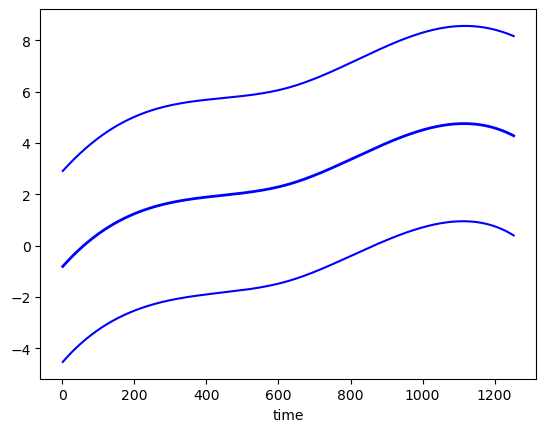

In [265]:
result.plot_partial(0)
plt.show()